![Banner](../images/09_04_banner_rs_uav.png)


# Panicle Detection with YOLO

Panicles per square metre is a direct component of rice yield.


## Overview

From late September the LUMS
frames show pale, cream-coloured panicles above the leaves, and the study counted them with a
fine-tuned YOLOv5 detector run in **sliding windows** (1024 px, stride 512) over the
orthomosaic, keeping boxes above 0.7 confidence and merging overlaps with non-maximum
suppression (NMS) at IoU 0.4. This notebook builds that pipeline with `rs.uav.tiled_detect`
and friends. A detector is any function `tile -> boxes`, so the windowing, merging, counting
and scoring are first checked on a synthetic scene with known answers and then run on real
frames with a simple colour-based candidate detector; the LUMS YOLOv5 weights plug into the
same call when downloaded.


## Core concepts

### Learning objectives

1. Lay out sliding windows and understand why objects cut by window edges inflate counts.
2. Merge window detections back into image coordinates with cross-window NMS.
3. Score detections against reference boxes: precision, recall, F1 and count agreement.
4. Convert boxes to polygons and compute panicles per m².
5. Run a YOLO model (ultralytics or YOLOv5) in the same pipeline and prepare a small labelled
   set for fine-tuning.

### Data

| Data | Type |
|---|---|
| LUMS rice frames, 17 Sep to 3 Oct 2025, panicle stage, 1.85 mm/px | **Real** (CC BY 4.0) |
| Synthetic scene with known boxes, used to check windowing and NMS | **Simulated** |
| The paper's reference panicle counts | Not in the public release |

### Contents

1. Setup
2. Sliding windows
3. Checking the machinery on a scene with known answers
4. Panicle candidates on real frames
5. Boxes to polygons and panicles per m²
6. YOLO in the same pipeline
7. Preparing a small labelled set for fine-tuning
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw boxes
import cv2  # colour conversion, connected components
from scipy import ndimage as ndi  # labelling blobs

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)
from geolattice.rsense.uav.detect import detection_windows  # window layout used by tiled_detect

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
LUMS = Path("../../../../Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
GSD = 0.00185  # m/px
RUN_DL = False  # True: download the LUMS YOLOv5 panicle weights (Google Drive) and run them

def draw_boxes(ax, boxes, color="yellow", lw=1.0):
    for b in boxes.itertuples():
        ax.add_patch(Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, color=color, lw=lw))

## Sliding windows

A 3840 × 2160 frame is larger than a detector's input. `detection_windows(H, W, window,
stride)` lays out windows with `stride` steps; with stride = window / 2 every object away from
the image border falls wholly inside at least one window. The last row and column of windows
are shifted back to end exactly at the image edge.


28 windows on (2160, 3840)


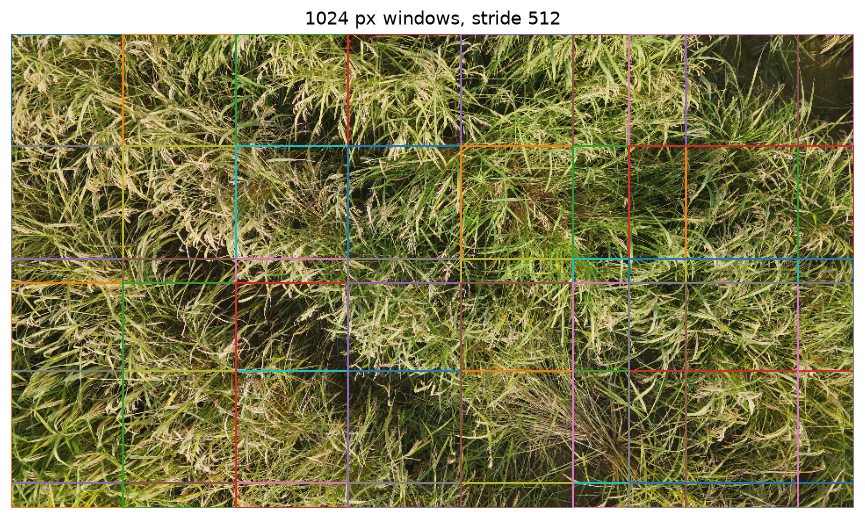

In [2]:
frame = sorted((LUMS / "2025-10-03").glob("*.png"))[1]
img = rs.uav.read_frame(frame, gsd=GSD)
H, W = img.sizes["y"], img.sizes["x"]
wins = detection_windows(H, W, window=1024, stride=512)
print(len(wins), "windows on", (H, W))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.imshow(rs.uav.to_rgb_array(img)[::4, ::4], extent=[0, W, H, 0])
for i, (r0, c0, h, w) in enumerate(wins):
    ax.add_patch(Rectangle((c0, r0), w, h, fill=False, color=f"C{i % 10}", lw=1.2))
ax.set_title("1024 px windows, stride 512"); ax.axis("off"); plt.show()

## Checking the machinery on a scene with known answers

Before trusting a count, check the windowing on a scene where the right answer is known. The
synthetic image below has 64 bright squares of 40 px on a dark background; the "detector"
finds bright connected components in a window and returns their boxes with confidence 0.95.
Squares cut by a window edge come back as partial boxes.


In [3]:
def square_detector(tile, conf):
    """Toy detector: boxes around bright connected components, confidence 0.95."""
    lab, _ = ndi.label(tile[..., 0] > 128)
    out = [[s[1].start, s[0].start, s[1].stop, s[0].stop, 0.95, 0] for s in ndi.find_objects(lab)]
    return np.array(out, np.float32).reshape(-1, 6)

scene = np.zeros((700, 900, 3), np.uint8)
truth = []
for r in range(30, 680, 90):
    for c in range(30, 880, 110):
        scene[r:r + 40, c:c + 40] = 255
        truth.append((c, r, c + 40, r + 40))
truth = pd.DataFrame(truth, columns=["x1", "y1", "x2", "y2"])
scene_img = rs.uav.as_image(scene)

rows = []
for label, kw in [("no NMS, keep edge boxes", dict(iou=1.01, edge_margin=0)),
                  ("NMS only", dict(iou=0.4, edge_margin=0)),
                  ("NMS + drop edge boxes", dict(iou=0.4, edge_margin=2))]:
    det = rs.uav.tiled_detect(scene_img, square_detector, window=256, stride=128, conf=0.5, **kw)
    rows.append({"setting": label, "detections": len(det), **rs.uav.detection_scores(det, truth, iou=0.5)})
pd.DataFrame(rows).set_index("setting").round(3)

,detections,tp,fp,fn,precision,recall,f1,count_agreement
setting,,,,,,,,
"no NMS, keep edge boxes",270,64,206,0,0.237,1.000,0.383,-2.219
NMS only,80,63,17,1,0.788,0.984,0.875,0.750
NMS + drop edge boxes,64,64,0,0,1.000,1.000,1.000,1.000


Without NMS every square is counted once per window that sees it. NMS merges full duplicates,
but a square cut by a window edge yields a **partial** box whose IoU with the full box is low,
so it survives NMS and inflates the count. Dropping boxes that touch an interior window edge
(`edge_margin`) removes them: the whole object is always found by a neighbouring window when
objects are smaller than the overlap (`window - stride`). For objects larger than the overlap,
set `edge_margin=0`.


## Panicle candidates on real frames

Without the trained weights, a simple colour rule stands in for the detector: panicles here
are pale cream clusters (bright, low saturation, yellowish hue) above green leaves. The
function below finds such pixels, joins them into blobs and returns a box per blob larger than
a few square centimetres, with a "confidence" equal to the fraction of candidate pixels in
the box (elongated, diagonal blobs fill little of their box, hence the low threshold of
0.15). It also fires on bright leaf midribs and dry leaf tips, so treat its output as
**candidates**; the point is to exercise the pipeline, not to replace a trained model.


In [4]:
def panicle_candidates(tile, conf, min_area_px=400, max_area_px=20_000):
    """Colour-blob stand-in detector: (n, 6) boxes [x1, y1, x2, y2, score, class]."""
    hsv = cv2.cvtColor(tile, cv2.COLOR_RGB2HSV_FULL).astype(np.float32)
    hue, sat, val = hsv[..., 0] * 360 / 255, hsv[..., 1], hsv[..., 2]
    cand = ((val > 180) & (sat > 30) & (sat < 90) & (hue > 35) & (hue < 80)).astype(np.uint8)
    cand = cv2.morphologyEx(cand, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))  # drop speckle
    n, lab, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    out = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if min_area_px <= a <= max_area_px:
            score = a / float(w * h)  # how much of the box the blob fills
            if score >= conf:
                out.append([x, y, x + w, y + h, score, 0])
    return np.array(out, np.float32).reshape(-1, 6)

boxes = rs.uav.tiled_detect(img, panicle_candidates, window=1024, stride=512, conf=0.15, iou=0.4)
print(len(boxes), "candidate boxes")
boxes.head()

243 candidate boxes


,x1,y1,x2,y2,confidence,class,cx,cy,x,y
0,1922.0,342.0,1936.0,402.0,0.709524,0,1929.0,372.0,3.568650,-0.688200
1,2350.0,81.0,2364.0,122.0,0.705575,0,2357.0,101.5,4.360450,-0.187775
2,2671.0,4.0,2686.0,48.0,0.703030,0,2678.5,26.0,4.955225,-0.048100
3,3564.0,1645.0,3610.0,1658.0,0.678930,0,3587.0,1651.5,6.635950,-3.055275
4,2504.0,1249.0,2517.0,1432.0,0.622110,0,2510.5,1340.5,4.644425,-2.479925


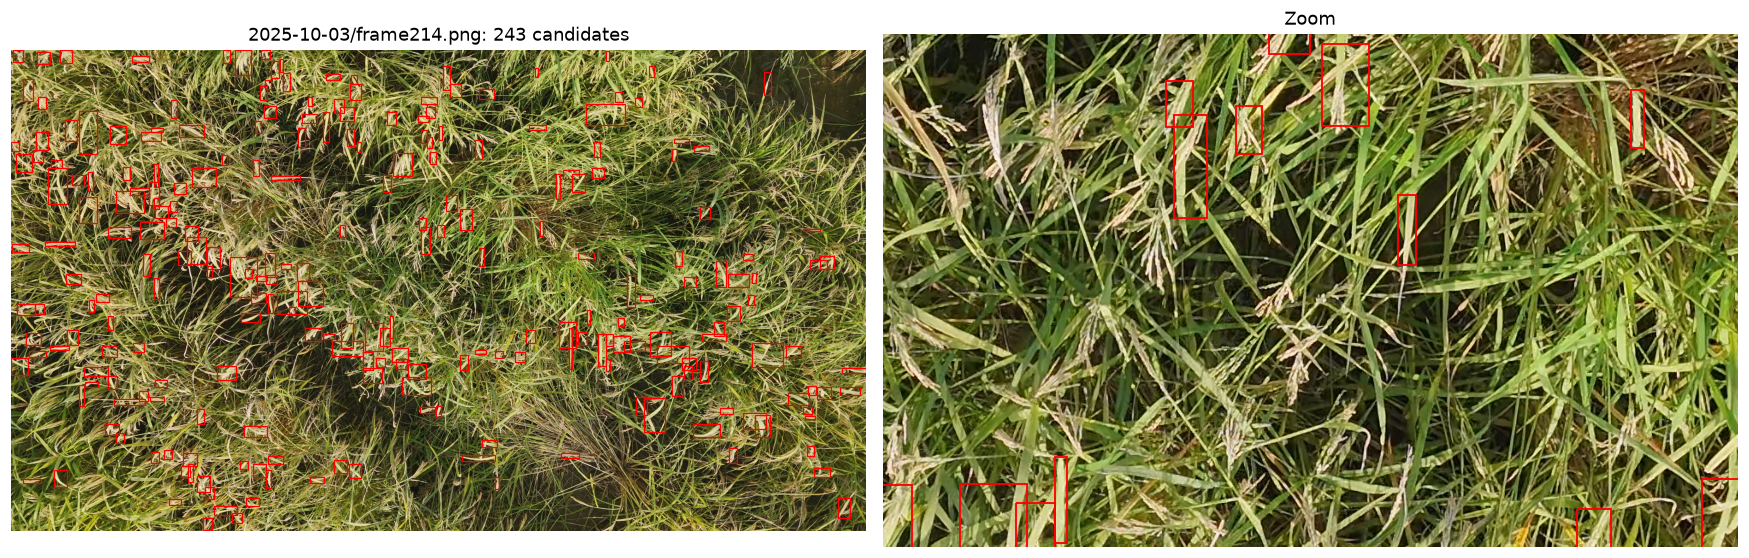

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rgb = rs.uav.to_rgb_array(img)
axes[0].imshow(rgb); draw_boxes(axes[0], boxes, "red", 0.8)
axes[0].set_title(f"{frame.parent.name}/{frame.name}: {len(boxes)} candidates")
zoom = (slice(700, 1300), slice(1500, 2500))
axes[1].imshow(rgb[zoom]); draw_boxes(axes[1], boxes.assign(x1=boxes.x1 - 1500, x2=boxes.x2 - 1500,
                                                             y1=boxes.y1 - 700, y2=boxes.y2 - 700), "red", 1.2)
axes[1].set_xlim(0, 1000); axes[1].set_ylim(600, 0); axes[1].set_title("Zoom")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

The zoom makes the limits plain: most visible panicles (the drooping cream clusters) are
missed, because they are thin and partly shaded, while several boxes sit on bright leaf
blades. Counts from this stand-in are not panicle counts; they only exercise the pipeline.


## Boxes to polygons and panicles per m²

`rs.uav.boxes_to_gdf` turns boxes into polygons in the image's coordinates (metres here, the
CRS for GeoTIFFs), and `rs.uav.count_summary` reports count, mean confidence and objects per
m² when the image has a GSD.


In [6]:
gdf = rs.uav.boxes_to_gdf(boxes, img)
print(gdf.geometry.area.describe().round(5))
rs.uav.count_summary(boxes, img)

count    243.00000
mean       0.01183
std        0.01081
min        0.00196
25%        0.00557
50%        0.00814
75%        0.01375
max        0.07516
dtype: float64


{'count': 243,
 'mean_confidence': 0.31840673089027405,
 'area_m2': 28.387584000000004,
 'per_m2': 8.56008035062089}

Across the panicle-stage dates (the frames come from different spots each date, so read the
spread, not single frames):


,mean,std,min,max
date,,,,
2025-09-17,1.51,1.04,0.07,3.06
2025-09-19,5.44,1.60,2.82,7.40
2025-09-26,3.68,1.32,1.83,6.02
2025-10-01,3.79,1.18,1.83,5.14
2025-10-03,7.67,1.42,5.07,10.11


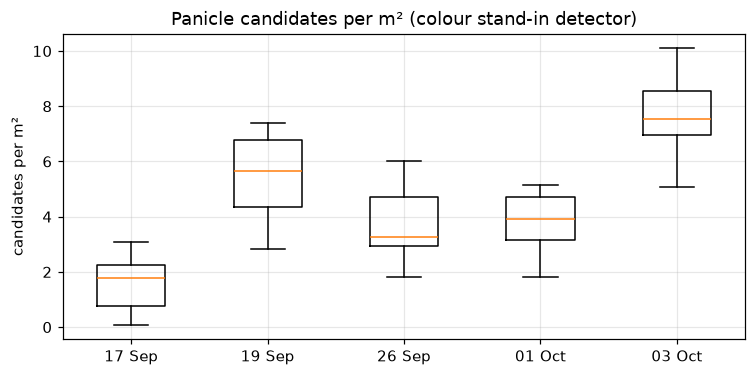

In [7]:
rows = []
for date in ["2025-09-17", "2025-09-19", "2025-09-26", "2025-10-01", "2025-10-03"]:
    for f in sorted((LUMS / date).glob("*.png")):
        im = rs.uav.read_frame(f, gsd=GSD)
        b = rs.uav.tiled_detect(im, panicle_candidates, window=1024, stride=512, conf=0.15, iou=0.4)
        rows.append({"date": pd.Timestamp(date), "frame": f.name, **rs.uav.count_summary(b, im)})
per_frame = pd.DataFrame(rows)
summary = per_frame.groupby("date").per_m2.agg(["mean", "std", "min", "max"]).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([g.per_m2 for _, g in per_frame.groupby("date")], tick_labels=[f"{d:%d %b}" for d in summary.index])
ax.set(ylabel="candidates per m²", title="Panicle candidates per m² (colour stand-in detector)"); ax.grid(alpha=0.3)
plt.show()
per_frame.to_csv(OUT / "panicle_candidates_frames.csv", index=False)

Candidate density is lowest on 17 September, when few panicles have emerged, and highest on
3 October, but it does not rise smoothly: 26 September and 1 October sit below 19 September.
Each date's frames come from different parts of the field, and a colour rule cannot tell
panicles from yellowing leaf tips, which increase over the same weeks (notebook 09_04_08).
Only a trained detector, checked against reference counts, separates the two.


## YOLO in the same pipeline

`rs.uav.load_detector(weights, backend=...)` wraps an ultralytics (YOLOv8/11) or YOLOv5 model as
a `tile -> boxes` function, and `tiled_detect` accepts the weights path directly. The LUMS
model is a fine-tuned YOLOv5 (`backend="yolov5"`, loaded through `torch.hub`).


In [8]:
if RUN_DL:
    weights = rs.uav.fetch_weights("yolov5_rice_panicle")
    yolo = rs.uav.load_detector(weights, backend="yolov5")
    det = rs.uav.tiled_detect(img, yolo, window=1024, stride=512, conf=0.7, iou=0.4, progress=True)
    print(rs.uav.count_summary(det, img))
    print("candidate detector vs YOLO:", rs.uav.detection_scores(boxes, det, iou=0.3))
    fig, ax = plt.subplots(figsize=(12, 6.8))
    ax.imshow(rgb); draw_boxes(ax, det, "cyan", 1.0); draw_boxes(ax, boxes, "red", 0.6)
    ax.set_title("YOLO (cyan) and colour candidates (red)"); ax.axis("off"); plt.show()
else:
    print("RUN_DL is False: YOLO skipped. Set RUN_DL = True to download the LUMS weights.")

RUN_DL is False: YOLO skipped. Set RUN_DL = True to download the LUMS weights.


## Preparing a small labelled set for fine-tuning

Detectors transfer poorly between varieties, growth stages and camera heights, so a few
hundred labelled panicles from your own fields usually pay off. The LUMS model was fine-tuned
from COCO weights. The workflow:

1. Cut frames into 1024 px tiles (the inference size) and keep tiles with panicles.
2. Label boxes in a tool such as CVAT or Label Studio, exported in YOLO format: one text file
   per tile, one line per box: `class x_centre y_centre width height`, all relative to the
   tile size.
3. Write a dataset YAML and train with ultralytics.

The cell below performs step 1 and writes YOLO-format label files from the candidate boxes,
purely to show the format; in practice you would correct these pseudo-labels by hand before
training.


In [9]:
ds = OUT / "yolo_panicles"
for sub in ["images/train", "labels/train"]:
    (ds / sub).mkdir(parents=True, exist_ok=True)
n_tiles = n_labels = 0
for r0, c0, h, w in detection_windows(H, W, 1024, 1024):  # non-overlapping tiles for training
    inside = boxes[(boxes.x1 >= c0) & (boxes.x2 <= c0 + w) & (boxes.y1 >= r0) & (boxes.y2 <= r0 + h)]
    if inside.empty:
        continue
    stem = f"{frame.parent.name}_{frame.stem}_{r0}_{c0}"
    cv2.imwrite(str(ds / "images/train" / f"{stem}.jpg"), cv2.cvtColor((rgb[r0:r0 + h, c0:c0 + w] * 255).astype(np.uint8), cv2.COLOR_RGB2BGR))
    xc = ((inside.x1 + inside.x2) / 2 - c0) / w; yc = ((inside.y1 + inside.y2) / 2 - r0) / h
    bw = (inside.x2 - inside.x1) / w; bh = (inside.y2 - inside.y1) / h
    lines = [f"0 {a:.6f} {b:.6f} {c:.6f} {d:.6f}" for a, b, c, d in zip(xc, yc, bw, bh)]
    (ds / "labels/train" / f"{stem}.txt").write_text("\n".join(lines) + "\n")
    n_tiles += 1; n_labels += len(lines)
(ds / "panicles.yaml").write_text(f"path: {ds.resolve()}\ntrain: images/train\nval: images/train\nnames:\n  0: panicle\n")
print(f"wrote {n_tiles} tiles and {n_labels} boxes to {ds}")
print((ds / "panicles.yaml").read_text())

wrote 12 tiles and 344 boxes to outputs/yolo_panicles
path: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_04_uav/outputs/yolo_panicles
train: images/train
val: images/train
names:
  0: panicle



Training then takes a few lines (not run here):

```python
from ultralytics import YOLO
model = YOLO("yolo11n.pt")                      # small COCO-pretrained model
model.train(data="outputs/yolo_panicles/panicles.yaml", imgsz=1024, epochs=100, batch=4)
det = rs.uav.tiled_detect(img, "runs/detect/train/weights/best.pt", backend="ultralytics", conf=0.5)
```

Keep a separate validation set from **different plots and dates** than the training tiles,
otherwise the scores measure memorisation, not detection.


## Summary and exercises

**Key points**

- A sliding window cuts panicles on the tile edge, so those boxes have to be dropped or they
  inflate the count. Overlapping windows are merged with NMS.
- Score the boxes against a reference: precision, recall, F1 and count agreement.
- Boxes become polygons, then panicles per square metre.
- A colour candidate detector and a YOLO model both go through `tiled_detect`. The windows,
  the merge and the count stay put when the detector changes.

**GeoLattice functions used:** `rs.uav.tiled_detect`, `rs.uav.detection_scores`, `rs.uav.boxes_to_gdf`,
`rs.uav.count_summary`, `rs.uav.load_detector`.

**Exercises**

1. In Section 3, make the squares 160 px (larger than the 128 px overlap) and compare
   `edge_margin=2` with `edge_margin=0`. Which is right now, and why?
2. Tighten `panicle_candidates` (e.g. `sat < 100`, larger `min_area_px`) and inspect what
   disappears in the zoom view: panicles or leaf tips?
3. Hand-label 30 panicles in one tile (x1, y1, x2, y2) and score the candidates with
   `detection_scores` at IoU 0.3 and 0.5.
4. With `RUN_DL = True`, compare YOLO counts per m² across dates with the candidate counts.

**References**

- Chaudhry, H., Rana, S. and Jaleel, A. (2026). *Computers and Electronics in Agriculture*
  (accepted). YOLOv5 panicle detection: 91.59 % accuracy.
- Redmon, J. et al. (2016). You only look once: unified, real-time object detection. *CVPR*.
- Jocher, G. et al. Ultralytics YOLO. https://github.com/ultralytics/ultralytics
- Neubeck, A. and Van Gool, L. (2006). Efficient non-maximum suppression. *ICPR*.
